# Pytorch Paper Replication

## 0. Getting Ready

In [1]:
# For this notebook to run with updated APIs, we need torch 1.12+ and torchvision 0.13+
try:
    import torch
    import torchvision
    assert int(torch.__version__.split(".")[1]) >= 12 or int(torch.__version__.split(".")[0]) == 2, "torch version should be 1.12+"
    assert int(torchvision.__version__.split(".")[1]) >= 13, "torchvision version should be 0.13+"
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")
except:
    print(f"[INFO] torch/torchvision versions not as required, installing nightly versions.")
    !pip3 install -U torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
    import torch
    import torchvision
    print(f"torch version: {torch.__version__}")
    print(f"torchvision version: {torchvision.__version__}")

torch version: 2.14.0+cu130
torchvision version: 0.29.0+cu130


In [2]:
# Continue with regular imports
import matplotlib.pyplot as plt
import torch
import torchvision

from torch import nn
from torchvision import transforms

# Try to get torchinfo, install it if it doesn't work
try:
    from torchinfo import summary
except:
    print("[INFO] Couldn't find torchinfo... installing it.")
    !pip install -q torchinfo
    from torchinfo import summary

# Try to import the going_modular directory, download it from GitHub if it doesn't work
try:
    from going_modular.going_modular import data_setup, engine
    from helper_functions import download_data, set_seeds, plot_loss_curves
except:
    # Get the going_modular scripts
    print("[INFO] Couldn't find going_modular or helper_functions scripts... downloading them from GitHub.")
    !git clone https://github.com/mrdbourke/pytorch-deep-learning
    !mv pytorch-deep-learning/going_modular .
    !mv pytorch-deep-learning/helper_functions.py . # get the helper_functions.py script
    !rm -rf pytorch-deep-learning
    from going_modular.going_modular import data_setup, engine
    from helper_functions import download_data, set_seeds, plot_loss_curves

/home/rayaa/miniconda3/envs/yolov7/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. Get Data

In [4]:
image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data/pizza_steak_sushi directory exists, skipping download.


PosixPath('data/pizza_steak_sushi')

In [5]:
train_dir = image_path / "train"
test_dir = image_path / "test"

## 2. Create Dataset and DataLoader

### 2.1 Create Manual Transform

In [6]:
IMG_SIZE = 224

manual_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
])
print(f"Manual transforms:\n{manual_transforms}")

Manual transforms:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
)


### 2.1 Create dataloader

In [7]:
BATcH_SIZE = 32

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    train_dir=train_dir,
    test_dir=test_dir,
    transform=manual_transforms,
    batch_size=BATcH_SIZE
)

train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x7d4b482271f0>,
 ['pizza', 'steak', 'sushi'])

### 2.2 Visualize one Image

In [8]:
image_batch, label_batch = next(iter(train_dataloader))

image,label = image_batch[0], label_batch[0]

image.shape, label

(torch.Size([3, 224, 224]), tensor(2))

(-0.5, 223.5, 223.5, -0.5)

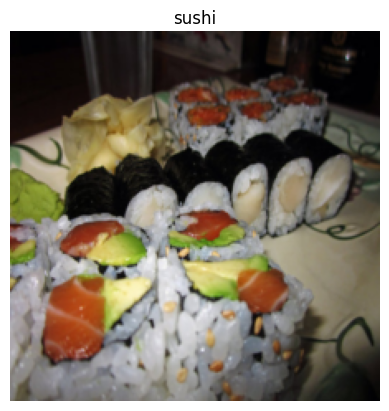

In [9]:
#Plot image with matplotlib
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)

## 3 About Paper Replicating

In this section mainly about the theories of the paper, You can read it in the website

## 4. Equation 1: Split data into patches and creating the class, position and patch embedding

### 4.1 Calculating patch embedding input and output shapes by hand

In [10]:
height = 224
width = 224
color_channels = 3
patch_size = 16

number_of_patches = int((height * width)/patch_size**2)
print(f"Number of patches (N) with image height (H={height}), width (W={width}) and patch size (P={patch_size}): {number_of_patches}")

Number of patches (N) with image height (H=224), width (W=224) and patch size (P=16): 196


In [11]:
embedding_layer_input_shape = (height, width, color_channels)
embedding_layer_output_shape = (number_of_patches, patch_size**2 * color_channels)

print(f"Input shape (single 2D image): {embedding_layer_input_shape}")
print(f"Output shape (single 2D image flattened into patches): {embedding_layer_output_shape}")

Input shape (single 2D image): (224, 224, 3)
Output shape (single 2D image flattened into patches): (196, 768)


### 4.2 Turning Single Image into Patches

(-0.5, 223.5, 223.5, -0.5)

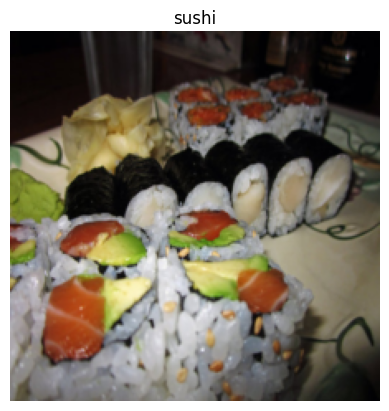

In [12]:
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)

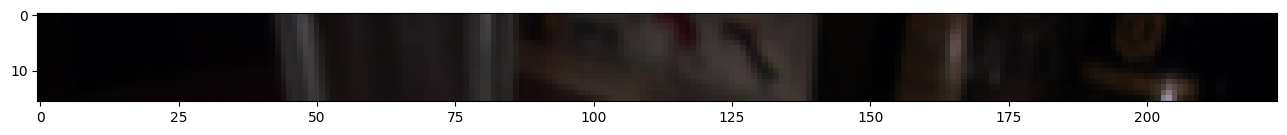

In [13]:
image_permuted = image.permute(1,2,0)

patch_size = 16
plt.figure(figsize=(patch_size,patch_size))
plt.imshow(image_permuted[:patch_size,:,:])

Number of patches per row: 14
Patch size: 16 pixels x 16 pixels


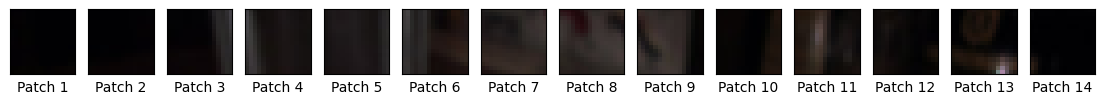

In [14]:
img_size = 224
patch_size = 16
num_patches = img_size // patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\nPatch size: {patch_size} pixels x {patch_size} pixels")

fig, axs = plt.subplots(nrows=1, ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True, sharey=True)

for i, patch in enumerate(range(0,img_size,patch_size)):
    axs[i].imshow(image_permuted[:patch_size,patch:patch+patch_size,:])
    axs[i].set_xlabel(f"Patch {i+1}")
    axs[i].set_xticks([])
    axs[i].set_yticks([])
    

Number of patches per row: 14.0        
Number of patches per column: 14.0        
Total patches: 196.0        
Patch size: 16 pixels x 16 pixels


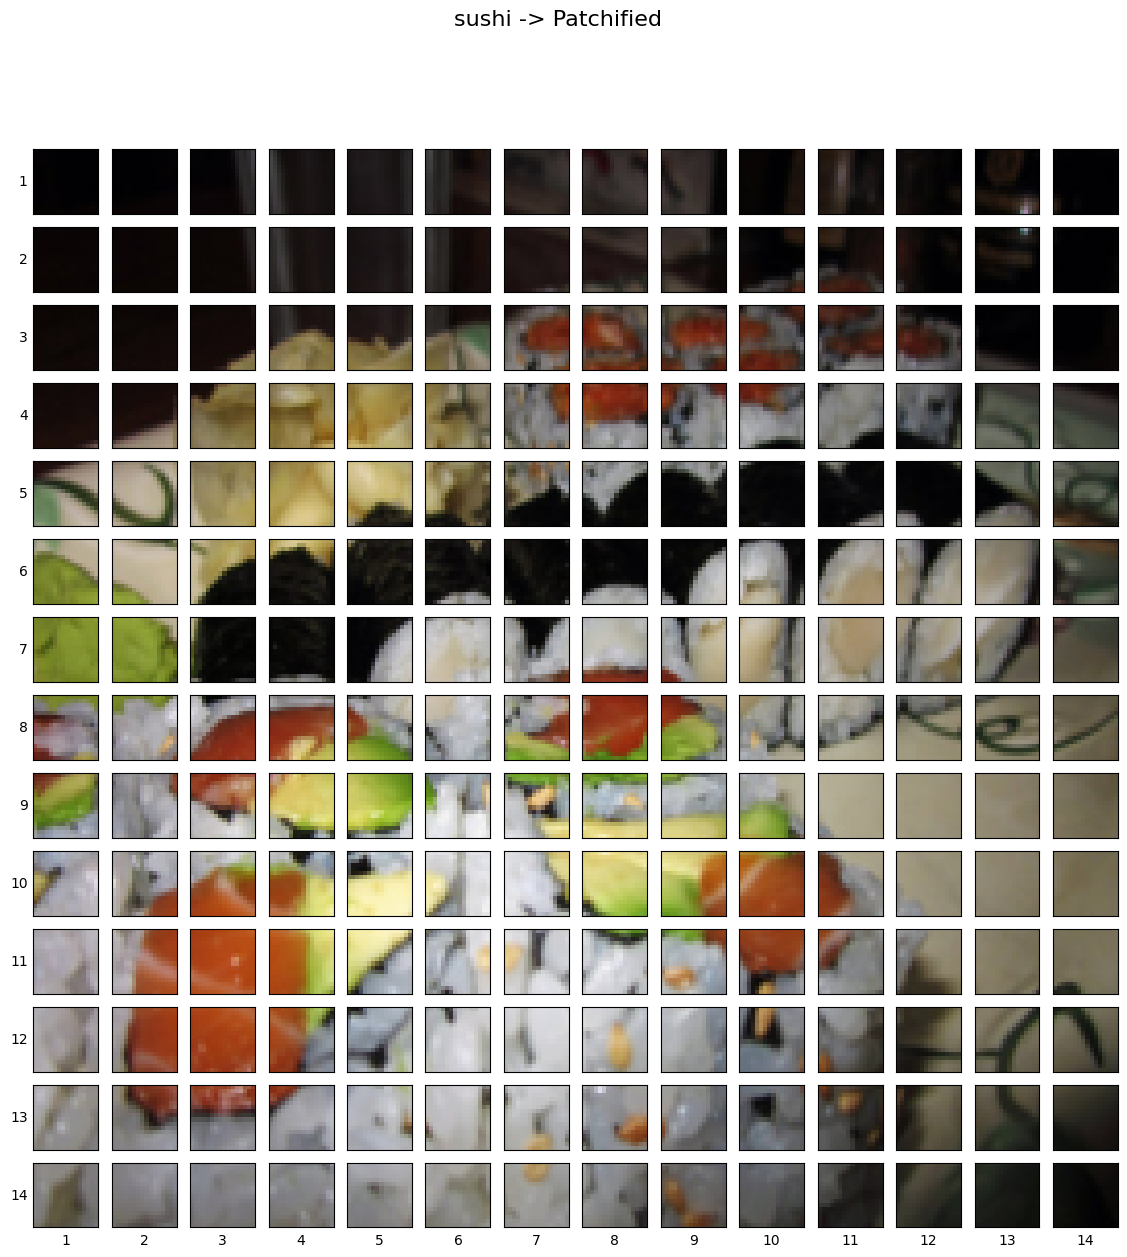

In [15]:
# Setup hyperparameters and make sure img_size and patch_size are compatible
img_size = 224
patch_size = 16
num_patches = img_size/patch_size
assert img_size % patch_size == 0, "Image size must be divisible by patch size"
print(f"Number of patches per row: {num_patches}\
        \nNumber of patches per column: {num_patches}\
        \nTotal patches: {num_patches*num_patches}\
        \nPatch size: {patch_size} pixels x {patch_size} pixels")

# Create a series of subplots
fig, axs = plt.subplots(nrows=img_size // patch_size, # need int not float
                        ncols=img_size // patch_size,
                        figsize=(num_patches, num_patches),
                        sharex=True,
                        sharey=True)

# Loop through height and width of image
for i, patch_height in enumerate(range(0, img_size, patch_size)): # iterate through height
    for j, patch_width in enumerate(range(0, img_size, patch_size)): # iterate through width

        # Plot the permuted image patch (image_permuted -> (Height, Width, Color Channels))
        axs[i, j].imshow(image_permuted[patch_height:patch_height+patch_size, # iterate through height
                                        patch_width:patch_width+patch_size, # iterate through width
                                        :]) # get all color channels

        # Set up label information, remove the ticks for clarity and set labels to outside
        axs[i, j].set_ylabel(i+1,
                             rotation="horizontal",
                             horizontalalignment="right",
                             verticalalignment="center")
        axs[i, j].set_xlabel(j+1)
        axs[i, j].set_xticks([])
        axs[i, j].set_yticks([])
        axs[i, j].label_outer()

# Set a super title
fig.suptitle(f"{class_names[label]} -> Patchified", fontsize=16)
plt.show()

### 4.3 Creating Image Patches with torch.nn.Conv2d()

In [16]:
# we can patch with convolutional layer with kernel_size dan stride = patch_size
from torch import nn

patch_size = 16

conv2d = nn.Conv2d(in_channels=3,
                   out_channels=768,
                   kernel_size=patch_size,
                   stride=patch_size,
                   padding=0)

In [17]:
# Pass the image through the convolutional layer
image_out_of_conv = conv2d(image.unsqueeze(0)) # add a single batch dimension (height, width, color_channels) -> (batch, height, width, color_channels)
print(image_out_of_conv.shape)

torch.Size([1, 768, 14, 14])


Showing random convolutional feature maps from indexes: [369, 230, 100, 588, 160]


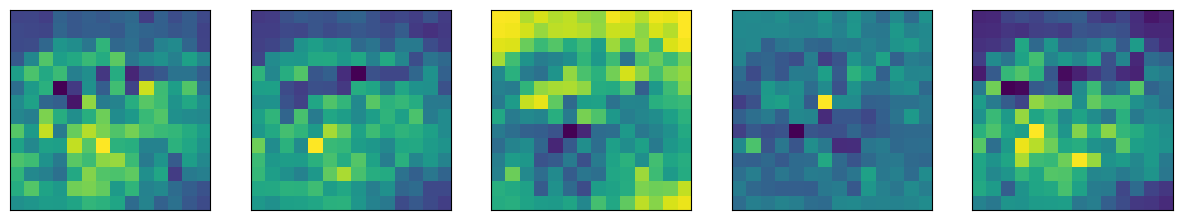

In [18]:
import random
random_indexes = random.sample(range(0,768),k=5)
print(f"Showing random convolutional feature maps from indexes: {random_indexes}")

fig,axs = plt.subplots(nrows=1, ncols=len(random_indexes),figsize=(15,15))

for i, idx in enumerate(random_indexes):
    image_conv_feature_map = image_out_of_conv[:,idx,:,:]
    axs[i].imshow(image_conv_feature_map.squeeze().detach().numpy())
    axs[i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

In [19]:
single_feature_map = image_out_of_conv[:,0,:,:]
single_feature_map, single_feature_map.requires_grad,single_feature_map.shape


(tensor([[[-0.0045,  0.0025,  0.0446, -0.0755,  0.0127, -0.0602,  0.0518,
            0.0028, -0.0103,  0.0014, -0.0484, -0.0152,  0.0477, -0.0222],
          [ 0.0057,  0.0057,  0.0137, -0.0608,  0.0210, -0.0881,  0.0200,
           -0.0338, -0.0951,  0.0441,  0.0149, -0.0760,  0.0832, -0.0029],
          [ 0.0124,  0.0096,  0.0233,  0.0940,  0.0808,  0.0739, -0.0507,
            0.0435,  0.1462,  0.0203, -0.0479, -0.1248, -0.0538, -0.0021],
          [-0.0017,  0.0634,  0.0882,  0.1965,  0.2064,  0.0548,  0.0312,
            0.0249,  0.1640, -0.1681, -0.0162,  0.0541, -0.0080, -0.0642],
          [ 0.0704,  0.0511,  0.1250,  0.2446,  0.1076,  0.0510,  0.0719,
           -0.0825,  0.1002, -0.0040,  0.0339, -0.1910,  0.0292,  0.0415],
          [ 0.1796,  0.1680, -0.1152,  0.2428,  0.0031,  0.0758, -0.0483,
           -0.1214,  0.3038, -0.2629,  0.1552,  0.0233, -0.0942,  0.0578],
          [ 0.2709,  0.1803, -0.1234,  0.0181,  0.4205,  0.0336, -0.1068,
            0.1676,  0.1313, -0.

## 4.4 Flattening the patch Embedding

In [20]:
# Current tensor shape
print(f"Current tensor shape: {image_out_of_conv.shape} -> [batch, embedding_dim, feature_map_height, feature_map_width]")

Current tensor shape: torch.Size([1, 768, 14, 14]) -> [batch, embedding_dim, feature_map_height, feature_map_width]


In [21]:
# Create flatten layer
flatten = nn.Flatten(start_dim=2, # flatten feature_map_height (dimension 2)
                     end_dim=3) # flatten feature_map_width (dimension 3)

Original image shape: torch.Size([3, 224, 224]) -> [height, width, color_channels]
Image shape after convolutional layer: torch.Size([1, 768, 14, 14]) -> [batch, embedding_dim, feature_map_height, feature_map_width]
Image shape after flattening: torch.Size([1, 768, 196]) -> [batch, embedding_dim, feature_map_height * feature_map_width]


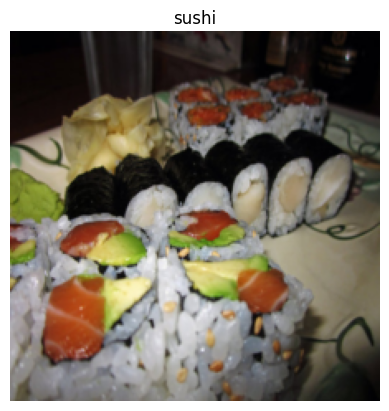

In [22]:
plt.imshow(image.permute(1,2,0))
plt.title(class_names[label])
plt.axis(False)
print(f"Original image shape: {image.shape} -> [height, width, color_channels]")

# turn into feature maps
image_out_of_conv = conv2d(image.unsqueeze(0)) # add a single batch dimension (height, width, color_channels) -> (batch, height, width, color_channels)
print(f"Image shape after convolutional layer: {image_out_of_conv.shape} -> [batch, embedding_dim, feature_map_height, feature_map_width]")

# flatten the feature maps
image_out_of_conv_flattened = flatten(image_out_of_conv)
print(f"Image shape after flattening: {image_out_of_conv_flattened.shape} -> [batch, embedding_dim, feature_map_height * feature_map_width]")

In [23]:
# Get flattened image patch embeddings in right shape
image_out_of_conv_flattened_reshaped = image_out_of_conv_flattened.permute(0, 2, 1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
print(f"Patch embedding sequence shape: {image_out_of_conv_flattened_reshaped.shape} -> [batch_size, num_patches, embedding_size]")

Patch embedding sequence shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


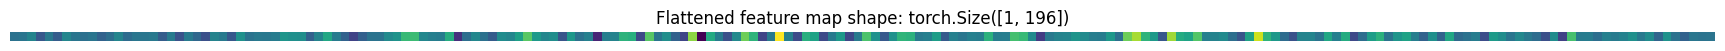

In [24]:
# Get a single flattened feature map
single_flattened_feature_map = image_out_of_conv_flattened_reshaped[:, :, 0] # index: (batch_size, number_of_patches, embedding_dimension)

# Plot the flattened feature map visually
plt.figure(figsize=(22, 22))
plt.imshow(single_flattened_feature_map.detach().numpy())
plt.title(f"Flattened feature map shape: {single_flattened_feature_map.shape}")
plt.axis(False);

In [25]:
# See the flattened feature map as a tensor
single_flattened_feature_map, single_flattened_feature_map.requires_grad, single_flattened_feature_map.shape

(tensor([[-0.0045,  0.0025,  0.0446, -0.0755,  0.0127, -0.0602,  0.0518,  0.0028,
          -0.0103,  0.0014, -0.0484, -0.0152,  0.0477, -0.0222,  0.0057,  0.0057,
           0.0137, -0.0608,  0.0210, -0.0881,  0.0200, -0.0338, -0.0951,  0.0441,
           0.0149, -0.0760,  0.0832, -0.0029,  0.0124,  0.0096,  0.0233,  0.0940,
           0.0808,  0.0739, -0.0507,  0.0435,  0.1462,  0.0203, -0.0479, -0.1248,
          -0.0538, -0.0021, -0.0017,  0.0634,  0.0882,  0.1965,  0.2064,  0.0548,
           0.0312,  0.0249,  0.1640, -0.1681, -0.0162,  0.0541, -0.0080, -0.0642,
           0.0704,  0.0511,  0.1250,  0.2446,  0.1076,  0.0510,  0.0719, -0.0825,
           0.1002, -0.0040,  0.0339, -0.1910,  0.0292,  0.0415,  0.1796,  0.1680,
          -0.1152,  0.2428,  0.0031,  0.0758, -0.0483, -0.1214,  0.3038, -0.2629,
           0.1552,  0.0233, -0.0942,  0.0578,  0.2709,  0.1803, -0.1234,  0.0181,
           0.4205,  0.0336, -0.1068,  0.1676,  0.1313, -0.1089,  0.0181,  0.1063,
          -0.114

### Putting Altogether

In [26]:
class PatchEmbedding(nn.Module):
    """Turns a 2D input image into a 1D sequence learnable embedding vector.

    Args:
        in_channels (int): Number of color channels for the input images. Defaults to 3.
        patch_size (int): Size of patches to convert input image into. Defaults to 16.
        embedding_dim (int): Size of embedding to turn image into. Defaults to 768.
    """
    
    def __init__(self, in_channels: int = 3, patch_size: int = 16, embedding_dim: int = 768):
        super().__init__()
        
        self.patcher = nn.Conv2d(in_channels = in_channels,
                                 out_channels = embedding_dim,
                                 kernel_size = patch_size,
                                 stride = patch_size,
                                 padding=0)
        
        self.flatten = nn.Flatten(start_dim=2, end_dim=3)
        
    def forward(self,x):
        image_resolution = x.shape[-1]
        assert image_resolution % patch_size == 0, f"Input image size ({image_resolution}) is not divisible by patch size ({patch_size})"
        
        x_patched = self.patcher(x)
        x_flattened = self.flatten(x_patched)
        
        return x_flattened.permute(0, 2, 1) # [batch_size, P^2•C, N] -> [batch_size, N, P^2•C]
        

In [27]:
# try it on single image
set_seeds()

patchify = PatchEmbedding(in_channels=3, patch_size=16, embedding_dim=768)


print(f"Input image shape: {image.unsqueeze(0).shape}")
patch_embedded_image = patchify(image.unsqueeze(0))
print(f"Output patch shape: {patch_embedded_image.shape} -> [batch_size, num_patches, embedding_size]")

Input image shape: torch.Size([1, 3, 224, 224])
Output patch shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


In [28]:
random_input_image = (1,3,224,224)
random_input_image_error = (1,3,250,250) # not divisible by patch size

summary(PatchEmbedding(),
        input_size=random_input_image,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                  Input Shape          Output Shape         Param #              Trainable
PatchEmbedding (PatchEmbedding)          [1, 3, 224, 224]     [1, 196, 768]        --                   True
├─Conv2d (patcher)                       [1, 3, 224, 224]     [1, 768, 14, 14]     590,592              True
├─Flatten (flatten)                      [1, 768, 14, 14]     [1, 768, 196]        --                   --
Total params: 590,592
Trainable params: 590,592
Non-trainable params: 0
Total mult-adds (M): 115.76
Input size (MB): 0.60
Forward/backward pass size (MB): 1.20
Params size (MB): 2.36
Estimated Total Size (MB): 4.17

### 4.6 Token Embedding

In [29]:
print(patch_embedded_image)
print(f"patch embedding shape: {patch_embedded_image.shape} -> [batch_size, num_patches, embedding_size]")

tensor([[[-0.0298, -0.0162, -0.0343,  ...,  0.0140, -0.0067,  0.0146],
         [-0.0356, -0.0084, -0.0363,  ...,  0.0227, -0.0129,  0.0087],
         [-0.1125,  0.0523, -0.0125,  ...,  0.0361, -0.0493,  0.0117],
         ...,
         [-0.2595,  0.0492, -0.0592,  ...,  0.1573, -0.0493,  0.0891],
         [-0.0904, -0.0158, -0.0505,  ...,  0.0786, -0.0628,  0.0481],
         [-0.0438, -0.0071, -0.0356,  ...,  0.0255, -0.0270,  0.0255]]],
       grad_fn=<PermuteBackward0>)
patch embedding shape: torch.Size([1, 196, 768]) -> [batch_size, num_patches, embedding_size]


In [30]:
batch_size = patch_embedded_image.shape[0]
embedding_dimension = patch_embedded_image.shape[-1]

class_token = nn.Parameter(torch.ones(batch_size,1,embedding_dimension),requires_grad=True)

print(class_token[:,:,:10])

print(f"Class token shape: {class_token.shape} -> [batch_size, 1, embedding_dimension]")

tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
Class token shape: torch.Size([1, 1, 768]) -> [batch_size, 1, embedding_dimension]


In [31]:
patch_embedded_image_with_class_embedding = torch.cat((class_token,patch_embedded_image),dim=1)
print(f"Patch embedded with class embedding shape: {patch_embedded_image_with_class_embedding.shape} -> [batch_size, num_patches + 1, embedding_size]")
print(patch_embedded_image_with_class_embedding)

Patch embedded with class embedding shape: torch.Size([1, 197, 768]) -> [batch_size, num_patches + 1, embedding_size]
tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
         [-0.0298, -0.0162, -0.0343,  ...,  0.0140, -0.0067,  0.0146],
         [-0.0356, -0.0084, -0.0363,  ...,  0.0227, -0.0129,  0.0087],
         ...,
         [-0.2595,  0.0492, -0.0592,  ...,  0.1573, -0.0493,  0.0891],
         [-0.0904, -0.0158, -0.0505,  ...,  0.0786, -0.0628,  0.0481],
         [-0.0438, -0.0071, -0.0356,  ...,  0.0255, -0.0270,  0.0255]]],
       grad_fn=<CatBackward0>)


### 4.7 Potitional Embedding

In [32]:
# View the sequence of patch embeddings with the prepended class embedding
patch_embedded_image_with_class_embedding, patch_embedded_image_with_class_embedding.shape

(tensor([[[ 1.0000,  1.0000,  1.0000,  ...,  1.0000,  1.0000,  1.0000],
          [-0.0298, -0.0162, -0.0343,  ...,  0.0140, -0.0067,  0.0146],
          [-0.0356, -0.0084, -0.0363,  ...,  0.0227, -0.0129,  0.0087],
          ...,
          [-0.2595,  0.0492, -0.0592,  ...,  0.1573, -0.0493,  0.0891],
          [-0.0904, -0.0158, -0.0505,  ...,  0.0786, -0.0628,  0.0481],
          [-0.0438, -0.0071, -0.0356,  ...,  0.0255, -0.0270,  0.0255]]],
        grad_fn=<CatBackward0>),
 torch.Size([1, 197, 768]))

In [33]:
# get number of patches
number_of_patches = int((height * width) / patch_size**2)

# get embedding dimension
embedding_dimension = patch_embedded_image_with_class_embedding.shape[2]

# create the learnable 1D position embedding parameter
position_embedding = nn.Parameter(torch.ones(1,number_of_patches + 1, embedding_dimension), requires_grad=True)


print(position_embedding[:,:10,:10])
print(position_embedding.shape)





tensor([[[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
         [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]], grad_fn=<SliceBackward0>)
torch.Size([1, 197, 768])


In [34]:
# Add the position embedding to the patch and class token embedding
patch_and_position_embedding = patch_embedded_image_with_class_embedding + position_embedding
print(patch_and_position_embedding)
print(f"Patch embeddings, class token prepended and positional embeddings added shape: {patch_and_position_embedding.shape} -> [batch_size, number_of_patches, embedding_dimension]")

tensor([[[2.0000, 2.0000, 2.0000,  ..., 2.0000, 2.0000, 2.0000],
         [0.9702, 0.9838, 0.9657,  ..., 1.0140, 0.9933, 1.0146],
         [0.9644, 0.9916, 0.9637,  ..., 1.0227, 0.9871, 1.0087],
         ...,
         [0.7405, 1.0492, 0.9408,  ..., 1.1573, 0.9507, 1.0891],
         [0.9096, 0.9842, 0.9495,  ..., 1.0786, 0.9372, 1.0481],
         [0.9562, 0.9929, 0.9644,  ..., 1.0255, 0.9730, 1.0255]]],
       grad_fn=<AddBackward0>)
Patch embeddings, class token prepended and positional embeddings added shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches, embedding_dimension]


### 4.8 putting all together

In [35]:
set_seeds()

# set patch size
patch_size = 16

# print shape of original tensor and get the dimension
print(f"Image tensor shape: {image.shape}")
height,width = image.shape[1], image.shape[2]


# get image tensor and add batch dimension
X = image.unsqueeze(0)
print(f"Image tensor with batch dimension shape: {X.shape}")

# create patch embedding layer
patch_embedding = PatchEmbedding(in_channels=3, patch_size=patch_size,embedding_dim=768)

# pass image through embedding layer
patch_embedding = patch_embedding(X)
print(f"Patch embedding shape: {patch_embedding.shape} -> [batch_size, number_of patches, embedding_dimension]")

# create token embedding
batch_size = patch_embedding.shape[0]
embedding_dimension = patch_embedding.shape[-1]
class_token = nn.Parameter(torch.ones(batch_size,1,embedding_dimension),requires_grad=True)
print(f"class token shape: {class_token.shape} -> [batch_size, 1, embedding_dimension]")

# prepend class token to patch embedding
patch_embedding_class_token = torch.cat((class_token,patch_embedding),dim=1)
print(f"Patch embedding with class token shape: {patch_embedding_class_token.shape} -> [batch_size, number_of_patches + 1, embedding_dimension]")

# create position embedding
number_of_patches = int((height * width) / patch_size**2)
postition_embedding  = nn.Parameter(torch.ones(1,number_of_patches + 1, embedding_dimension), requires_grad=True)

# add position embedding to patch embedding with class token
patch_and_position_embedding = patch_embedding_class_token + postition_embedding
print(f"Patch embedding with class token and position embedding shape: {patch_and_position_embedding.shape} -> [batch_size, number_of_patches + 1, embedding_dimension]")


Image tensor shape: torch.Size([3, 224, 224])
Image tensor with batch dimension shape: torch.Size([1, 3, 224, 224])
Patch embedding shape: torch.Size([1, 196, 768]) -> [batch_size, number_of patches, embedding_dimension]
class token shape: torch.Size([1, 1, 768]) -> [batch_size, 1, embedding_dimension]
Patch embedding with class token shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches + 1, embedding_dimension]
Patch embedding with class token and position embedding shape: torch.Size([1, 197, 768]) -> [batch_size, number_of_patches + 1, embedding_dimension]
